# Employee Attrition Prediction – Model Development
**Course:** Machine Learning for Business Applications | **Task:** Binary classification

## Part A – Business Problem Definition
**Business Problem:** The company is losing employees, and replacing them is expensive (recruiting, training, lost productivity). HR wants to know *which current employees are most at risk of leaving* so it can act before they resign.

**Analytics Objective:** Build a classification model that predicts whether an employee is likely to leave.

**Target Variable:** `Attrition` (Yes = left, No = stayed), encoded as 1/0.

**Business Decision:** Employees flagged as high-risk are prioritised for retention actions (stay interview, workload review, compensation review, career-path discussion).

## Dataset
- **Name:** IBM HR Analytics Employee Attrition & Performance
- **Source:** IBM data scientists' fictional dataset, widely published on Kaggle; copy used here from the IBM `employee-attrition-aif360` GitHub repository.
- **Rows × Columns:** 1,470 × 35
- **Business meaning of target:** 1 = employee left the company, 0 = employee stayed.

### Variable descriptions
| Variable | Type | Role | Meaning |
|---|---|---|---|
| Attrition | Categorical (Yes/No) | **Target** | Whether the employee left the company (encoded 1 = left, 0 = stayed) |
| Age | Numeric | Predictor | Employee age in years |
| MonthlyIncome | Numeric | Predictor | Monthly salary |
| DistanceFromHome | Numeric | Predictor | Distance from home to workplace |
| YearsAtCompany | Numeric | Predictor | Years with the company |
| TotalWorkingYears | Numeric | Predictor | Total career experience in years |
| NumCompaniesWorked | Numeric | Predictor | Number of previous employers |
| YearsSinceLastPromotion | Numeric | Predictor | Years since last promotion |
| OverTime | Categorical (Yes/No) | Predictor | Whether the employee works overtime |
| BusinessTravel | Categorical | Predictor | Non-Travel, Travel_Rarely or Travel_Frequently |
| JobSatisfaction | Ordered category 1-4 | Predictor | 1 = Low ... 4 = Very High |
| WorkLifeBalance | Ordered category 1-4 | Predictor | 1 = Bad ... 4 = Best |
| EnvironmentSatisfaction | Ordered category 1-4 | Predictor | 1 = Low ... 4 = Very High |
| JobLevel | Ordered category 1-5 | Predictor | Seniority level |
| StockOptionLevel | Ordered category 0-3 | Predictor | Stock option tier |

Excluded on purpose: Gender and MaritalStatus (fairness), plus the constant columns and the employee ID dropped during cleaning. Remaining dataset columns not used as predictors were left out to keep the model simple and explainable.


In [1]:
import pandas as pd, numpy as np, joblib
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, roc_auc_score)
sns.set_theme(style='whitegrid')
df = pd.read_csv('../data/dataset.csv')

## Part B – Data Preparation
### B1–B2: Loading & understanding

In [2]:
print(df.shape); df.head()

(1470, 35)


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   Age                       1470 non-null   int64
 1   Attrition                 1470 non-null   str  
 2   BusinessTravel            1470 non-null   str  
 3   DailyRate                 1470 non-null   int64
 4   Department                1470 non-null   str  
 5   DistanceFromHome          1470 non-null   int64
 6   Education                 1470 non-null   int64
 7   EducationField            1470 non-null   str  
 8   EmployeeCount             1470 non-null   int64
 9   EmployeeNumber            1470 non-null   int64
 10  EnvironmentSatisfaction   1470 non-null   int64
 11  Gender                    1470 non-null   str  
 12  HourlyRate                1470 non-null   int64
 13  JobInvolvement            1470 non-null   int64
 14  JobLevel                  1470 non-null   int64
 15

In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Age,1470.0,36.923810,9.135373,18.0,30.00,36.0,43.00,60.0
DailyRate,1470.0,802.485714,403.509100,102.0,465.00,802.0,1157.00,1499.0
DistanceFromHome,1470.0,9.192517,8.106864,1.0,2.00,7.0,14.00,29.0
Education,1470.0,2.912925,1.024165,1.0,2.00,3.0,4.00,5.0
EmployeeCount,1470.0,1.000000,0.000000,1.0,1.00,1.0,1.00,1.0
EmployeeNumber,1470.0,1024.865306,602.024335,1.0,491.25,1020.5,1555.75,2068.0
EnvironmentSatisfaction,1470.0,2.721769,1.093082,1.0,2.00,3.0,4.00,4.0
HourlyRate,1470.0,65.891156,20.329428,30.0,48.00,66.0,83.75,100.0
JobInvolvement,1470.0,2.729932,0.711561,1.0,2.00,3.0,3.00,4.0
JobLevel,1470.0,2.063946,1.106940,1.0,1.00,2.0,3.00,5.0


### B3: Data cleaning

In [5]:
print('Missing values :', df.isna().sum().sum())
print('Duplicate rows  :', df.duplicated().sum())
const = [c for c in df.columns if df[c].nunique()==1]
print('Constant columns:', const)

Missing values : 0
Duplicate rows  : 0
Constant columns: ['EmployeeCount', 'Over18', 'StandardHours']


**Findings:** no missing values and no duplicates. Three columns (`EmployeeCount`, `Over18`, `StandardHours`) have a single value for everyone, so they carry no information. `EmployeeNumber` is just an ID. All four are dropped.

In [6]:
df = df.drop(columns=const + ['EmployeeNumber'])
# Outlier check (IQR) on income – kept, because high earners are real senior staff, not errors
q1,q3 = df.MonthlyIncome.quantile([.25,.75]); iqr=q3-q1
print('Income outliers:', ((df.MonthlyIncome>q3+1.5*iqr)).sum(), 'of', len(df))
df['Attrition_flag'] = (df.Attrition=='Yes').astype(int)
print(df.Attrition.value_counts(normalize=True).round(3))

Income outliers: 114 of 1470
Attrition
No     0.839
Yes    0.161
Name: proportion, dtype: float64


Income outliers are genuine senior employees, so they are **kept**. Logistic regression is sensitive to scale, so numeric features are standardised later.
The target is **imbalanced** (about 16% left), so accuracy alone will be misleading – see the evaluation section.

### B4: Feature preparation
- **Target:** `Attrition_flag`
- **Numerical predictors:** Age, MonthlyIncome, DistanceFromHome, YearsAtCompany, TotalWorkingYears, NumCompaniesWorked, YearsSinceLastPromotion
- **Categorical predictors:** OverTime, BusinessTravel, JobSatisfaction, WorkLifeBalance, JobLevel, StockOptionLevel, EnvironmentSatisfaction (the 1–4 ratings and levels are ordered categories, treated as categories)
- Gender and MaritalStatus are deliberately **not** used as predictors to avoid discriminatory decisions.

## Part C – Exploratory Data Analysis

/tmp/ipykernel_184/4143455614.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Attrition', palette=['#4C78A8','#E45756'], ax=ax)


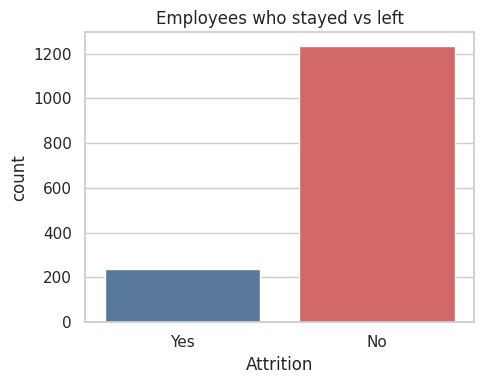

In [7]:
fig, ax = plt.subplots(figsize=(5,4))
sns.countplot(data=df, x='Attrition', palette=['#4C78A8','#E45756'], ax=ax)
ax.set_title('Employees who stayed vs left'); plt.tight_layout()
plt.savefig('../images/eda_target.png', dpi=130); plt.show()

**Insight 1:** About 16% of employees (237 of 1,470) left. That is a meaningful loss rate, but the classes are imbalanced, so a model that always says "stays" would be 84% accurate and completely useless to HR. We must judge the model on how many leavers it catches (recall), not accuracy.

/tmp/ipykernel_184/2378927079.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=r.index, y=r.values, palette=['#4C78A8','#E45756'], ax=ax)


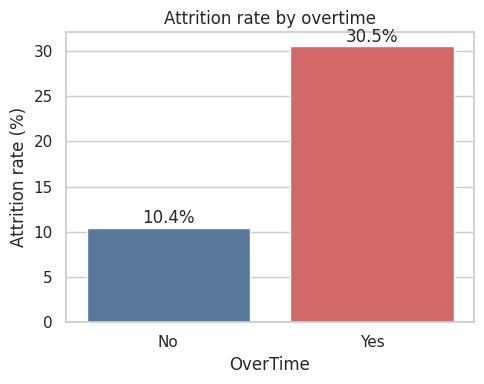

In [8]:
fig, ax = plt.subplots(figsize=(5,4))
r = df.groupby('OverTime').Attrition_flag.mean()*100
sns.barplot(x=r.index, y=r.values, palette=['#4C78A8','#E45756'], ax=ax)
ax.set_ylabel('Attrition rate (%)'); ax.set_title('Attrition rate by overtime')
for i,v in enumerate(r.values): ax.text(i,v+.5,f'{v:.1f}%',ha='center')
plt.tight_layout(); plt.savefig('../images/eda_overtime.png', dpi=130); plt.show()

**Insight 2:** Employees who work overtime leave at about 30.5%, nearly three times the rate of those who do not (10.4%). Overtime is a controllable lever: HR can review workloads and overtime policy for teams with heavy overtime.

/tmp/ipykernel_184/3164737125.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Attrition', y='MonthlyIncome', palette=['#4C78A8','#E45756'], ax=ax)


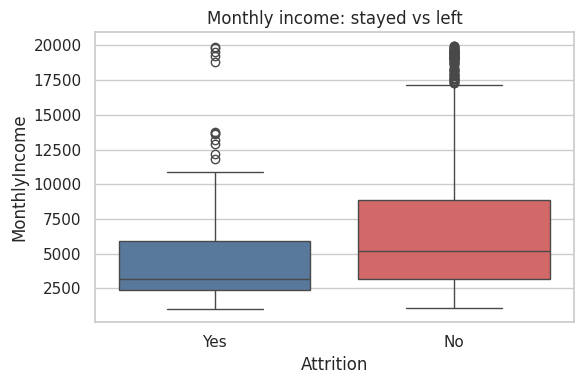

Attrition
No     5204.0
Yes    3202.0
Name: MonthlyIncome, dtype: float64


In [9]:
fig, ax = plt.subplots(figsize=(6,4))
sns.boxplot(data=df, x='Attrition', y='MonthlyIncome', palette=['#4C78A8','#E45756'], ax=ax)
ax.set_title('Monthly income: stayed vs left'); plt.tight_layout()
plt.savefig('../images/eda_income.png', dpi=130); plt.show()
print(df.groupby('Attrition').MonthlyIncome.median())

**Insight 3:** The median income of leavers (about 3,200) is much lower than that of stayers (about 5,200). Lower-paid employees are more likely to leave, so pay reviews should focus on lower income bands rather than being applied across the board.

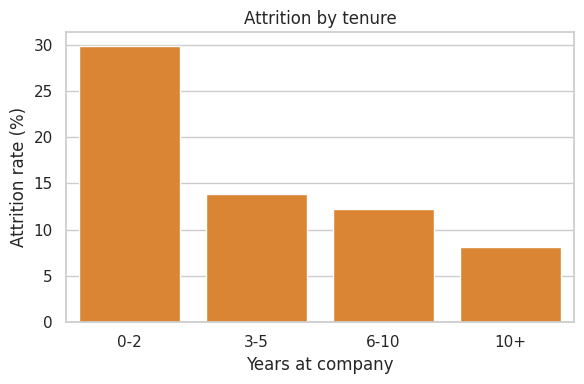

In [10]:
fig, ax = plt.subplots(figsize=(6,4))
g = df.groupby(pd.cut(df.YearsAtCompany,[-1,2,5,10,50],labels=['0-2','3-5','6-10','10+'])).Attrition_flag.mean()*100
sns.barplot(x=g.index.astype(str), y=g.values, color='#F58518', ax=ax)
ax.set_xlabel('Years at company'); ax.set_ylabel('Attrition rate (%)'); ax.set_title('Attrition by tenure')
plt.tight_layout(); plt.savefig('../images/eda_tenure.png', dpi=130); plt.show()

**Insight 4:** Employees in their first two years leave at about 30%, falling to about 8% after ten years. The early period is the highest-risk window, which points to onboarding and first-year engagement as the place to invest retention effort.

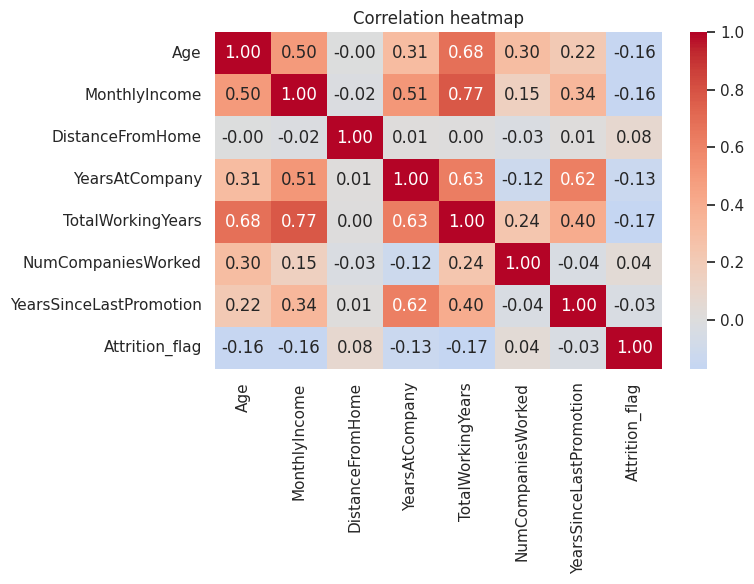

In [11]:
num_cols = ['Age','MonthlyIncome','DistanceFromHome','YearsAtCompany','TotalWorkingYears','NumCompaniesWorked','YearsSinceLastPromotion','Attrition_flag']
fig, ax = plt.subplots(figsize=(8,6))
sns.heatmap(df[num_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=ax)
ax.set_title('Correlation heatmap'); plt.tight_layout()
plt.savefig('../images/eda_corr.png', dpi=130); plt.show()

**Insight 5:** Attrition is negatively correlated with age, income, tenure and total experience: younger, newer, lower-paid staff leave more. Several of these predictors are strongly correlated with each other (e.g. income, experience and tenure), so individual coefficients should be interpreted with care.

## Part D – Machine Learning Model

In [12]:
num = ['Age','MonthlyIncome','DistanceFromHome','YearsAtCompany','TotalWorkingYears','NumCompaniesWorked','YearsSinceLastPromotion']
cat = ['OverTime','BusinessTravel','JobSatisfaction','WorkLifeBalance','JobLevel','StockOptionLevel','EnvironmentSatisfaction']
X = df[num+cat]; y = df['Attrition_flag']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
print(X_train.shape, X_test.shape)

(1176, 14) (294, 14)


**Why stratify?** It keeps the 16% / 84% class ratio the same in train and test sets.
**Why Logistic Regression?** It gives a probability of leaving (useful for ranking employees), its coefficients are easy to explain to HR managers, and `class_weight='balanced'` handles the imbalance. A Random Forest was also tested (below) for comparison.

In [13]:
pre = ColumnTransformer([('num', StandardScaler(), num),
                        ('cat', OneHotEncoder(handle_unknown='ignore'), cat)])
model = Pipeline([('pre', pre),
                  ('clf', LogisticRegression(max_iter=2000, class_weight='balanced'))])
model.fit(X_train, y_train)
y_pred = model.predict(X_test); y_prob = model.predict_proba(X_test)[:,1]

## Model Evaluation

Accuracy : 0.769
Precision: 0.387
Recall   : 0.766
F1 Score : 0.514
ROC-AUC  : 0.836


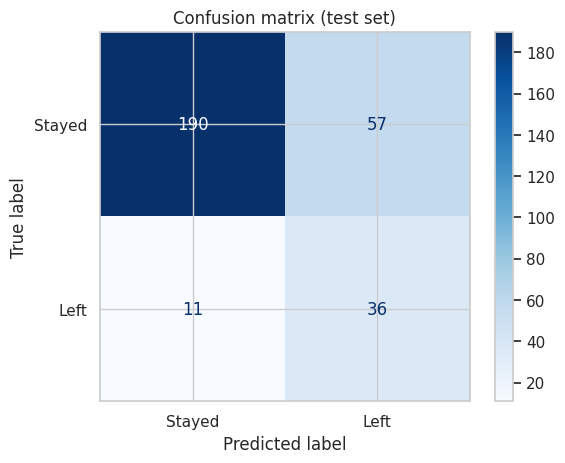

In [14]:
print(f'Accuracy : {accuracy_score(y_test,y_pred):.3f}')
print(f'Precision: {precision_score(y_test,y_pred):.3f}')
print(f'Recall   : {recall_score(y_test,y_pred):.3f}')
print(f'F1 Score : {f1_score(y_test,y_pred):.3f}')
print(f'ROC-AUC  : {roc_auc_score(y_test,y_prob):.3f}')
ConfusionMatrixDisplay(confusion_matrix(y_test,y_pred), display_labels=['Stayed','Left']).plot(cmap='Blues')
plt.title('Confusion matrix (test set)'); plt.savefig('../images/confusion_matrix.png', dpi=130); plt.show()

**Which metric matters most? Recall.** A false negative (missing someone who is about to leave) costs the company a replacement, typically a large share of annual salary. A false positive (flagging someone who would have stayed) costs only a conversation or a small retention gesture. Missing leavers is far more costly than over-flagging, so we prioritise recall, while watching precision so HR is not flooded with false alarms.

**Reading the confusion matrix:** of the 47 employees in the test set who actually left, the model catches 36 (recall about 77%) and misses 11. It also flags 57 employees who stayed (false alarms), which is why precision is only about 39%. This is an accepted trade-off for a low-cost intervention.

**Why accuracy is not the headline:** a model that predicts "stays" for everyone would score about 84% accuracy and catch zero leavers.

In [15]:
# Comparison with Random Forest
from sklearn.ensemble import RandomForestClassifier
rf = Pipeline([('pre',pre),('clf',RandomForestClassifier(300,class_weight='balanced',min_samples_leaf=5,random_state=42))]).fit(X_train,y_train)
p = rf.predict(X_test)
print('Random Forest -> Accuracy %.3f | Precision %.3f | Recall %.3f | F1 %.3f' % (
      accuracy_score(y_test,p), precision_score(y_test,p), recall_score(y_test,p), f1_score(y_test,p)))

Random Forest -> Accuracy 0.813 | Precision 0.413 | Recall 0.404 | F1 0.409


The Random Forest has higher accuracy but catches far fewer leavers (recall about 40%), so Logistic Regression is chosen.

## Part D (continued) - Which factors matter?


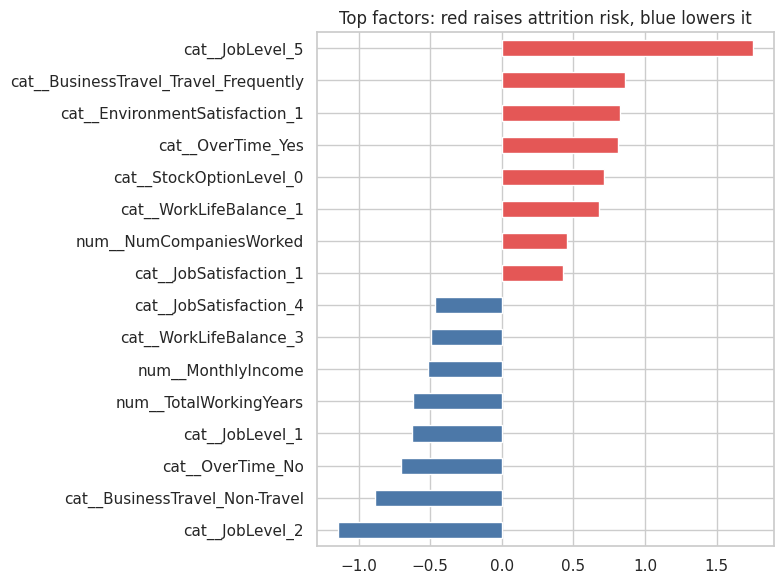

In [16]:
names = model.named_steps['pre'].get_feature_names_out()
coef = pd.Series(model.named_steps['clf'].coef_[0], index=names).sort_values()
top = pd.concat([coef.head(8), coef.tail(8)])
fig, ax = plt.subplots(figsize=(8,6))
top.plot.barh(color=['#4C78A8' if v<0 else '#E45756' for v in top], ax=ax)
ax.set_title('Top factors: red raises attrition risk, blue lowers it'); plt.tight_layout()
plt.savefig('../images/feature_importance.png', dpi=130); plt.show()

**What the chart shows:** the strongest factors that *raise* predicted attrition risk are frequent business travel, low environment satisfaction (rating 1), working overtime, having no stock options, and poor work-life balance (rating 1). Factors that *lower* risk are not travelling, no overtime, more total working experience, higher income and high job satisfaction.

**Caution:** Job Level 5 shows up as a risk factor, but there are only 69 such employees and job level is strongly correlated with income and experience, so this coefficient is unstable and should not be over-interpreted. Logistic regression coefficients show association, not proof of cause.

## Part E - Business Interpretation (TEAM TO WRITE)
Answer each question below in your own words, using the evidence pointers. Aim for 3-5 sentences each. Delete the pointers once you have written your answer.

### 1. What does the model predict?
*Evidence to use:* the target variable, what 1 and 0 mean, and whether the output is a label, a probability, or both.

**Your answer:** _..._

### 2. How accurate / useful is the model?
*Evidence to use:* the metrics table, the confusion matrix (190 / 57 / 11 / 36), the 84% always-stays baseline, and the Random Forest comparison. Ask: useful compared with what alternative?

**Your answer:** _..._

### 3. Which factors appear important?
*Evidence to use:* the feature-importance chart and EDA insights 2-4. Ask: which factors can the company actually change, and which can it not? What does the Job Level 5 caution mean for how far you trust the chart?

**Your answer:** _..._

### 4. What business decision can be made using the model?
*Evidence to use:* the risk levels and recommended actions in page 3 of the app. Ask: who in the company acts on the output, and what do they do differently?

**Your answer:** _..._

### 5. What are the limitations of the model?
*Evidence to use:* dataset origin (fictional, single snapshot), sample size (1,470 rows, 237 leavers), test set size (47 leavers), precision of about 39%, association vs causation, and the excluded variables.

**Your answer:** _..._

### 6. What could happen if the model makes a wrong prediction?
*Evidence to use:* think about both error types separately: a missed leaver (false negative) and a false alarm (false positive). Who is affected in each case, and what does each cost the company and the employee?

**Your answer:** _..._


## Part G – Save the model

In [17]:
joblib.dump(model, '../model.pkl')
print('Saved. Reload test:', joblib.load('../model.pkl').predict_proba(X_test.iloc[:1])[0])

Saved. Reload test: [0.82485488 0.17514512]
